# 🗄️ Archiviazione Vettoriale

**Argomenti trattati:**
1. Cosa sono gli embedding e come crearli
2. Come archiviare embedding in ChromaDB
3. Ricerca per similarità (similarity search)
4. Ranking dei risultati
5. Algoritmi di ricerca vettoriale usati da ChromaDB
6. Confronto tra diversi approcci di ricerca

---
> **Ambiente:** assicurati di aver attivato il virtualenv e installato le dipendenze (vedi `setup.txt`).

Creazione virtualenv: python3 -m venv .venv <br>
Usa vscode e attivalo selezionando il kernel il alto a destra <br>

> Esegui la cella di installazione qui sotto prima di procedere.

## 📦 Installazione delle dipendenze

In [1]:
# Esegui questa cella UNA SOLA VOLTA per installare le librerie necessarie
%pip install chromadb sentence-transformers numpy scikit-learn matplotlib

  Using cached bcrypt-5.0.0-cp39-abi3-win_amd64.whl.metadata (10 kB)
  Using cached tenacity-9.1.4-py3-none-any.whl.metadata (1.2 kB)
   ---------------------------------------- 0.0/23.5 MB ? eta -:--:--
   ---------------------------------------- 0.0/23.5 MB ? eta -:--:--
   ---------------------------------------- 0.0/23.5 MB ? eta -:--:--
   ---------------------------------------- 0.0/23.5 MB ? eta -:--:--
   ---------------------------------------- 0.0/23.5 MB ? eta -:--:--
   ---------------------------------------- 0.0/23.5 MB ? eta -:--:--
   ---------------------------------------- 0.0/23.5 MB ? eta -:--:--
   ---------------------------------------- 0.3/23.5 MB ? eta -:--:--
   ---------------------------------------- 0.3/23.5 MB ? eta -:--:--
   ---------------------------------------- 0.3/23.5 MB ? eta -:--:--
    --------------------------------------- 0.5/23.5 MB 409.6 kB/s eta 0:00:57
    --------------------------------------- 0.5/23.5 MB 409.6 kB/s eta 0:00:57
    ----

In [19]:
import chromadb
print(chromadb.__version__)

1.5.9


---
# PARTE 1 — Esempi Guidati
---

## 1. Cosa sono gli Embedding?

Un **embedding** è una rappresentazione numerica (vettore) di un testo.  
Testi semanticamente simili producono vettori vicini nello spazio ad alta dimensione.

```
"gatto"   → [0.12, -0.43, 0.87, ...]
"felino"  → [0.11, -0.41, 0.85, ...]   ← molto vicino a "gatto"
"aereo"   → [-0.90, 0.33, -0.12, ...]  ← lontano da entrambi
```

Il modello che useremo è `all-MiniLM-L6-v2` (384 dimensioni), leggero e scaricabile gratuitamente da HuggingFace.

In [2]:
from sentence_transformers import SentenceTransformer
import numpy as np

# Carica il modello (il download avviene automaticamente la prima volta)
model = SentenceTransformer("all-MiniLM-L6-v2")

frasi = [
    "Il gatto dorme sul divano.",
    "Un felino riposa sul sofà.",
    "L'aereo atterra all'aeroporto.",
]

# Genera gli embedding
vettori = model.encode(frasi)

print(f"\nNumero di frasi   : {len(frasi)}")
print(f"Dimensioni vettore: {vettori.shape[1]}")
print(f"\nPrimo vettore (prime 8 dimensioni):\n{vettori[0][:8]}")

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]


Numero di frasi   : 3
Dimensioni vettore: 384

Primo vettore (prime 8 dimensioni):
[-0.05954063  0.0171099  -0.03549254  0.00316507 -0.06842778  0.01808946
  0.07678527  0.03983127]


### 1.1 Similarità coseno

La **similarità coseno** misura l'angolo tra due vettori:

$$\text{cosine\_sim}(A, B) = \frac{A \cdot B}{\|A\| \cdot \|B\|}$$

- Valore **1.0** → vettori identici
- Valore **0.0** → vettori ortogonali (nessuna relazione)
- Valore **-1.0** → vettori opposti

In [3]:
from sklearn.metrics.pairwise import cosine_similarity

#Genero la matrice di similarità tra i vettori
sim_matrix = cosine_similarity(vettori)

print("Matrice di similarità coseno:\n")

etichette = ["gatto", "felino", "aereo"]
header = f"{'':>10}" + "".join(f"{e:>10}" for e in etichette)
print(header)

for i, riga in enumerate(sim_matrix):
    print(f"{etichette[i]:>10}" + "".join(f"{v:10.4f}" for v in riga))

Matrice di similarità coseno:

               gatto    felino     aereo
     gatto    1.0000    0.5252    0.3670
    felino    0.5252    1.0000    0.4292
     aereo    0.3670    0.4292    1.0000


---
## 2. ChromaDB — Archiviazione degli Embedding

**ChromaDB** è un database vettoriale open-source pensato per applicazioni AI.  
Permette di:
- **Archiviare** documenti con i loro embedding
- **Interrogare** la collezione con una query testuale
- **Filtrare** i risultati per metadati

### Architettura ChromaDB

```
Client
  └── Collection  (es. "articoli_scienza")
        ├── documento 1  → embedding + metadati
        ├── documento 2  → embedding + metadati
        └── ...
```

In [4]:
from typing import cast
import chromadb
from chromadb.utils.embedding_functions import SentenceTransformerEmbeddingFunction
from chromadb.api.types import EmbeddingFunction

# Client in-memory (nessun file su disco, perfetto per esperimenti)
client = chromadb.Client()

# Funzione di embedding integrata con SentenceTransformers
ef = SentenceTransformerEmbeddingFunction(
    model_name="all-MiniLM-L6-v2"
)

# Crea (o ottieni, se già esiste) una collezione
collezione = client.get_or_create_collection(
    name="articoli_scienza",
    embedding_function=cast(EmbeddingFunction, ef),
    metadata={"hnsw:space": "cosine"}   # metrica di distanza (similarità) e struttura dati (HNSW)
)

print("Collezione creata:", collezione.name)

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Collezione creata: articoli_scienza


### 2.1 Inserimento dei documenti

In [5]:
from chromadb.api.types import Metadata

documenti = [
    "I buchi neri sono regioni dello spazio-tempo con gravità estrema.",
    "Le stelle di neutroni sono tra gli oggetti più densi dell'universo.",
    "La fotosintesi permette alle piante di produrre glucosio dalla luce solare.",
    "Il DNA è la molecola che codifica le informazioni genetiche.",
    "Il teorema di Pitagora descrive il rapporto tra i lati di un triangolo rettangolo.",
    "Le onde gravitazionali sono increspature nello spazio-tempo previste da Einstein.",
    "I ribosomi sono organelli cellulari responsabili della sintesi proteica.",
    "Il principio di indeterminazione di Heisenberg limita la precisione di certe misure.",
    "La tavola periodica organizza gli elementi chimici per numero atomico.",
    "Le galassie a spirale contengono miliardi di stelle e immensi campi di gas.",
]

metadati: list[Metadata] = [
    {"categoria": "astrofisica",  "difficolta": "alta"},
    {"categoria": "astrofisica",  "difficolta": "alta"},
    {"categoria": "biologia",     "difficolta": "media"},
    {"categoria": "biologia",     "difficolta": "media"},
    {"categoria": "matematica",   "difficolta": "bassa"},
    {"categoria": "astrofisica",  "difficolta": "alta"},
    {"categoria": "biologia",     "difficolta": "alta"},
    {"categoria": "fisica",       "difficolta": "alta"},
    {"categoria": "chimica",      "difficolta": "media"},
    {"categoria": "astrofisica",  "difficolta": "media"},
]

ids = [f"doc_{i}" for i in range(len(documenti))]

collezione.add(
    documents=documenti,
    metadatas=metadati,
    ids=ids
)

print(f"Documenti inseriti: {collezione.count()}")

Documenti inseriti: 10


---
## 3. Ricerca per Similarità

La **ricerca per similarità** trova i documenti il cui vettore è più vicino al vettore della query.

ChromaDB restituisce sempre:
- `documents`: il testo dei risultati
- `distances`: la distanza (o dissimilarità) rispetto alla query
- `metadatas`: i metadati associati
- `ids`: gli identificativi

In [6]:
query = "Cosa dice il Teorema di Pitagora?"

risultati = collezione.query(
    query_texts=[query],
    n_results=3
)

documents = risultati["documents"]
distances = risultati["distances"]

if documents is None or distances is None:
    raise ValueError("La query non ha restituito documenti o distanze")

print(f"Query: '{query}'\n")
print(f"{'#':<4} {'Distanza':<12} Documento")
print("-" * 70)

for i, (doc, dist) in enumerate(zip(documents[0], distances[0])):
    print(f"{i+1:<4} {dist:<12.4f} {doc}")

Query: 'Cosa dice il Teorema di Pitagora?'

#    Distanza     Documento
----------------------------------------------------------------------
1    0.2323       Il teorema di Pitagora descrive il rapporto tra i lati di un triangolo rettangolo.
2    0.4711       I buchi neri sono regioni dello spazio-tempo con gravità estrema.
3    0.4756       Le galassie a spirale contengono miliardi di stelle e immensi campi di gas.


### 3.1 Ricerca con filtro sui metadati

ChromaDB supporta filtri **`where`** che agiscono come clausole SQL `WHERE`.  
Puoi filtrare per categoria, data, autore, o qualsiasi campo nei metadati.

In [7]:
query = "molecole e strutture cellulari"

# Cerca SOLO tra i documenti di biologia
risultati_filtrati = collezione.query(
    query_texts=[query],
    n_results=3,
    where={"categoria": "biologia"}     # Filtriamo i risultati
)

documents = risultati_filtrati["documents"]
distances = risultati_filtrati["distances"]
metadatas = risultati_filtrati["metadatas"]

if (
    documents is None or distances is None or metadatas is None
):
    raise ValueError("La query non ha restituito tutti i campi richiesti")

print(f"Query: '{query}'  |  Filtro: categoria = biologia\n")

for i, (doc, dist, meta) in enumerate(
    zip(
        documents[0],
        distances[0],
        metadatas[0]
    ),
    start=1
):
    print(
        f"{i}. [{dist:.4f}] "
        f"({meta['categoria']}, {meta['difficolta']}) "
        f"{doc}"
    )

Query: 'molecole e strutture cellulari'  |  Filtro: categoria = biologia

1. [0.5140] (biologia, alta) I ribosomi sono organelli cellulari responsabili della sintesi proteica.
2. [0.5639] (biologia, media) Il DNA è la molecola che codifica le informazioni genetiche.
3. [0.5898] (biologia, media) La fotosintesi permette alle piante di produrre glucosio dalla luce solare.


---
## 4. Ranking dei Risultati

ChromaDB restituisce i risultati già **ordinati per distanza crescente** (più vicino = più rilevante).  
Possiamo convertire la distanza coseno in un **punteggio di similarità** più intuitivo:

$$\text{similarity\_score} = 1 - \text{distance}$$

Con `hnsw:space = cosine`, la distanza è compresa in \[0, 2\], quindi:  
- `distance = 0.0` → documenti identici → `score = 1.0`  
- `distance = 1.0` → ortogonali → `score = 0.0`  
- `distance = 2.0` → opposti → `score = -1.0`

Query: 'oggetti nello spazio profondo'

Rank   Score    Documento
---------------------------------------------------------------------------
1      0.6008   I buchi neri sono regioni dello spazio-tempo con gravità estrema.
2      0.5695   Le onde gravitazionali sono increspature nello spazio-tempo previste d
3      0.5553   Le stelle di neutroni sono tra gli oggetti più densi dell'universo.
4      0.4849   Il teorema di Pitagora descrive il rapporto tra i lati di un triangolo
5      0.4689   Il DNA è la molecola che codifica le informazioni genetiche.


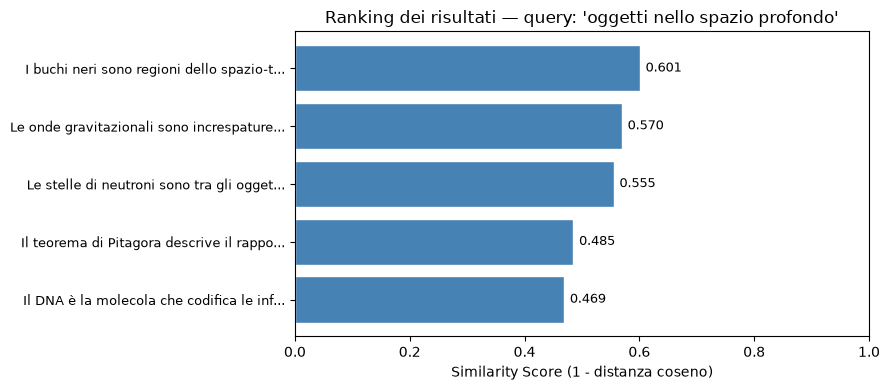

In [8]:
import matplotlib.pyplot as plt

query = "oggetti nello spazio profondo"

risultati = collezione.query(
    query_texts=[query],
    n_results=5
)

docs   = risultati["documents"][0]
dists  = risultati["distances"][0]
scores = [1 - d for d in dists]   # converti in similarity score

# Tabella testuale
print(f"Query: '{query}'\n")
print(f"{'Rank':<6} {'Score':<8} Documento")
print("-" * 75)
for rank, (doc, score) in enumerate(zip(docs, scores), start=1):
    print(f"{rank:<6} {score:<8.4f} {doc[:70]}")

# Grafico a barre orizzontale
etichette_brevi = [d[:40] + "..." if len(d) > 40 else d for d in docs]
fig, ax = plt.subplots(figsize=(9, 4))
bars = ax.barh(range(len(scores)), scores, color="steelblue", edgecolor="white")
ax.set_yticks(range(len(etichette_brevi)))
ax.set_yticklabels(etichette_brevi, fontsize=9)
ax.set_xlabel("Similarity Score (1 - distanza coseno)")
ax.set_title(f"Ranking dei risultati — query: '{query}'")
ax.invert_yaxis()
ax.set_xlim(0, 1)
for bar, score in zip(bars, scores):
    ax.text(score + 0.01, bar.get_y() + bar.get_height() / 2,
            f"{score:.3f}", va="center", fontsize=9)
plt.tight_layout()
plt.show()

---
## 5. Algoritmi di Ricerca Vettoriale in ChromaDB

ChromaDB utilizza internamente **HNSW** *(Hierarchical Navigable Small World)* come indice di default.  
Capire il funzionamento degli algoritmi è fondamentale per scegliere le impostazioni giuste.

### 5.1 Brute-Force (baseline)

Calcola la distanza tra la query e **tutti** i documenti.  
- ✅ Sempre esatto
- ❌ Complessità O(n·d) — lento su grandi collezioni

### 5.2 HNSW — Hierarchical Navigable Small World

Struttura a grafo multi-livello: i livelli superiori fungono da "autostrade", quelli inferiori da strade locali.  
La ricerca parte dall'alto e si avvicina progressivamente alla query.

```
Livello 2 (pochi nodi)  →  navigazione grossolana
Livello 1               →  navigazione intermedia
Livello 0 (tutti i nodi)→  ricerca fine
```

<b>Chroma fa già questa suddivisione per noi!<b>

**Parametri chiave:**
| Parametro | Significato | Default ChromaDB |
|-----------|-------------|------------------|
| `hnsw:M` | Connessioni per nodo | 16 |
| `hnsw:ef_construction` | Ampiezza ricerca durante la costruzione | 200 |
| `hnsw:ef` | Ampiezza ricerca durante la query | 10 |
| `hnsw:space` | Metrica di distanza (`cosine`, `l2`, `ip`) | `l2` |

### 5.3 Metriche di distanza supportate

| Metrica | Formula | Quando usarla |
|---------|---------|---------------|
| `cosine` | $1 - \cos(\theta)$ | Testi, semantica |
| `l2` | $\sqrt{\sum(a_i - b_i)^2}$ | Dati normalizzati, immagini |
| `ip` (inner product) | $-\sum a_i b_i$ | Embedding già normalizzati |

In [9]:
# Demo: confronto brute-force manuale vs ChromaDB HNSW

from sklearn.metrics.pairwise import cosine_distances
import time

query_testo = "stelle e galassie lontane"
query_vec   = model.encode([query_testo])   # shape (1, 384)  Utilizzo il modello di encoding per ccalcolare il vettore della query

############ BRUTE FORCE ############
# 1) Recupera tutti i vettori dalla collezione (sfrutto la collezione di Chroma)
tutti = collezione.get(include=["embeddings", "documents"])
tutti_vettori = np.array(tutti["embeddings"])  # shape (n, 384)
tutti_docs    = tutti["documents"]

# 2) Brute-force: calcola tutte le distanze coseno
distanze_bf = cosine_distances(query_vec, tutti_vettori)[0]
ordine_bf   = np.argsort(distanze_bf)[:3]

print("=== Brute-Force (top 3) ===")
for rank, idx in enumerate(ordine_bf, 1):
    print(f"  {rank}. [dist={distanze_bf[idx]:.4f}] {tutti_docs[idx][:70]}")


############ HNSW ############
# 3) HNSW tramite ChromaDB
risultati_hnsw = collezione.query(query_texts=[query_testo], n_results=3)

print("\n=== HNSW ChromaDB (top 3) ===")
for rank, (doc, dist) in enumerate(
    zip(risultati_hnsw["documents"][0], risultati_hnsw["distances"][0]), 1
):
    print(f"  {rank}. [dist={dist:.4f}] {doc[:70]}")

=== Brute-Force (top 3) ===
  1. [dist=0.3545] Le galassie a spirale contengono miliardi di stelle e immensi campi di
  2. [dist=0.5396] Le stelle di neutroni sono tra gli oggetti più densi dell'universo.
  3. [dist=0.5400] I buchi neri sono regioni dello spazio-tempo con gravità estrema.

=== HNSW ChromaDB (top 3) ===
  1. [dist=0.3545] Le galassie a spirale contengono miliardi di stelle e immensi campi di
  2. [dist=0.5396] Le stelle di neutroni sono tra gli oggetti più densi dell'universo.
  3. [dist=0.5400] I buchi neri sono regioni dello spazio-tempo con gravità estrema.


---
## 6. Confronto funzioni per calcolare la similarità

Confronteremo tre configurazioni:
1. **Cosine** (raccomandata per testi)
2. **L2** (distanza euclidea)
3. **Inner Product** (prodotto scalare)

## Confronto Diretto: Distanza Euclidea vs Cosine Similarity vs Prodotto Scalare

| Caratteristica | Distanza Euclidea | Cosine Similarity | Prodotto Scalare (Dot Product) |
|---------------|-------------------|-------------------|-------------------------------|
| **Cosa misura?** | La **distanza in linea retta** tra due punti nello spazio. | Il **coseno dell'angolo** tra due vettori. | La **combinazione di direzione e magnitudo** (lunghezza) dei vettori. |
| **Sensibilità alla scala?** | **Sì.** Aumenta all'aumentare della lunghezza dei vettori. | **No.** Ignora la lunghezza e isola puramente la direzione. | **Sì (estremamente).** Vettori più lunghi generano prodotti scalari molto più alti. |
| **Range dei valori** | Da **0** a **∞**. | Da **-1** a **1** (da **0** a **1** se i dati sono solo positivi). | Da **-∞** a **+∞**. |
| **Significato di "0"** | Identità perfetta (i due punti coincidono). | Vettori ortogonali (nessuna relazione/indipendenti). | Vettori ortogonali (nessuna relazione/indipendenti). |
| **Tipo di metrica** | È una **distanza** (valori bassi = alta similarità). | È una **similarità** (valori alti = alta similarità). | È una **misura di intensità** (valori positivi alti = alta similarità e magnitudo). |

In [10]:
# Ricrea tre collezioni con metriche diverse e inserisci gli stessi documenti

def crea_e_popola(client: chromadb.ClientAPI, nome, metrica):
    col = client.get_or_create_collection(
        name=nome,
        embedding_function=ef,
        metadata={"hnsw:space": metrica}
    )
    col.add(documents=documenti, metadatas=metadati, ids=ids)
    return col

# Nuovo client per avere uno spazio pulito
client2 = chromadb.Client()

col_cosine = crea_e_popola(client2, "cosine_col", "cosine")
col_l2     = crea_e_popola(client2, "l2_col",     "l2")
col_ip     = crea_e_popola(client2, "ip_col",     "ip")

print("Collezioni create:", [col_cosine.name, col_l2.name, col_ip.name])

Collezioni create: ['cosine_col', 'l2_col', 'ip_col']


In [11]:
query_confronto = "struttura dell'universo e della materia"

configurazioni = [
    ("Cosine",         col_cosine),
    ("L2 (euclidea)",  col_l2),
    ("Inner Product",  col_ip),
]

for nome, col in configurazioni:
    res = col.query(query_texts=[query_confronto], n_results=3)
    print(f"\n{'='*60}")
    print(f"Metrica: {nome}")
    print(f"{'='*60}")
    for rank, (doc, dist) in enumerate(
        zip(res["documents"][0], res["distances"][0]), 1
    ):
        print(f"  {rank}. [dist={dist:.4f}] {doc[:65]}")


Metrica: Cosine
  1. [dist=0.3876] Le stelle di neutroni sono tra gli oggetti più densi dell'univers
  2. [dist=0.5271] Le onde gravitazionali sono increspature nello spazio-tempo previ
  3. [dist=0.5415] I buchi neri sono regioni dello spazio-tempo con gravità estrema.

Metrica: L2 (euclidea)
  1. [dist=0.7753] Le stelle di neutroni sono tra gli oggetti più densi dell'univers
  2. [dist=1.0542] Le onde gravitazionali sono increspature nello spazio-tempo previ
  3. [dist=1.0830] I buchi neri sono regioni dello spazio-tempo con gravità estrema.

Metrica: Inner Product
  1. [dist=0.3876] Le stelle di neutroni sono tra gli oggetti più densi dell'univers
  2. [dist=0.5271] Le onde gravitazionali sono increspature nello spazio-tempo previ
  3. [dist=0.5415] I buchi neri sono regioni dello spazio-tempo con gravità estrema.


### 6.1 Visualizzazione degli embedding in 2D (PCA)

Riduciamo gli embedding a 2 dimensioni con **PCA** per visualizzare come i documenti si distribuiscono nello spazio.

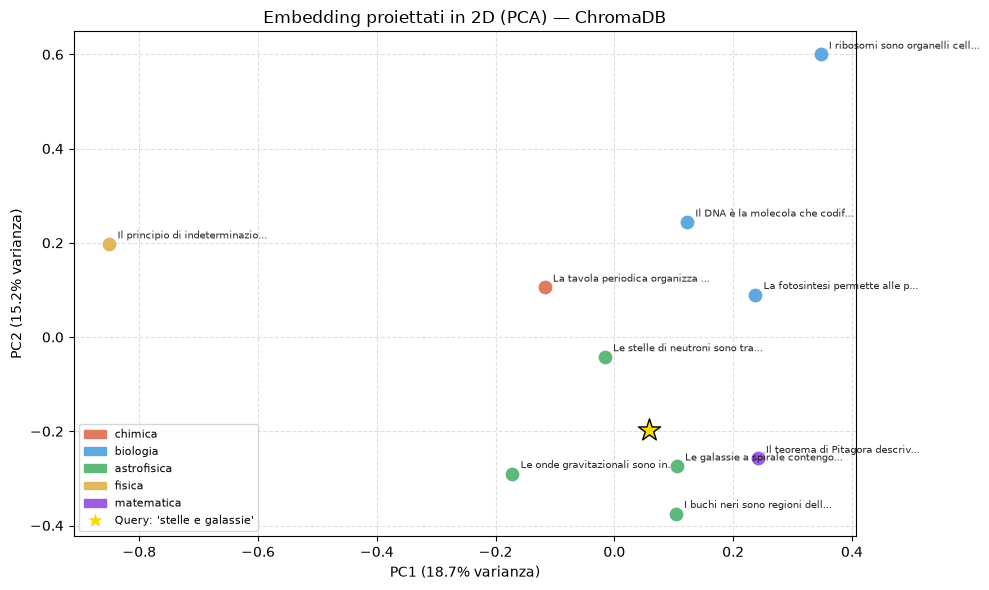

In [12]:
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

# Recupera vettori e metadati
dati = col_cosine.get(include=["embeddings", "documents", "metadatas"])
vettori_np  = np.array(dati["embeddings"])
etichette_p = [d[:30] + "..." for d in dati["documents"]]
categorie   = [m["categoria"] for m in dati["metadatas"]]

# Riduci a 2D
pca  = PCA(n_components=2)
coord_2d = pca.fit_transform(vettori_np)

# Colori per categoria
categorie_uniche = list(set(categorie))
colori_mappa = dict(zip(categorie_uniche,
                        ["#e07b5f", "#5fa8e0", "#5fb87a", "#e0b95f", "#9a5fe0"]))

fig, ax = plt.subplots(figsize=(10, 6))
for i, (x, y, etichetta, cat) in enumerate(
    zip(coord_2d[:, 0], coord_2d[:, 1], etichette_p, categorie)
):
    ax.scatter(x, y, color=colori_mappa[cat], s=80, zorder=3)
    ax.annotate(etichetta, (x, y), textcoords="offset points",
                xytext=(6, 4), fontsize=7.5, alpha=0.85)

# Aggiunge la query come stella
query_vis = "stelle e galassie"
qv = model.encode([query_vis])
q2d = pca.transform(qv)
ax.scatter(q2d[0, 0], q2d[0, 1], marker="*", s=280, color="gold",
           edgecolors="black", zorder=5, label=f"Query: '{query_vis}'")

legenda_cat = [mpatches.Patch(color=colori_mappa[c], label=c) for c in categorie_uniche]
ax.legend(handles=legenda_cat + [plt.Line2D([0], [0], marker="*", color="w",
          markerfacecolor="gold", markersize=14, label=f"Query: '{query_vis}'")],
          fontsize=8, loc="lower left")

ax.set_title("Embedding proiettati in 2D (PCA) — ChromaDB")
ax.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]*100:.1f}% varianza)")
ax.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]*100:.1f}% varianza)")
ax.grid(True, linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

---
## 7. Persistenza su disco

Per salvare il database usa `chromadb.PersistentClient`.

In [13]:
import os

# Percorso della cartella dove salvare il DB
DB_PATH = "./DATABASE/lezione_db"
os.makedirs(DB_PATH, exist_ok=True)

client_persistente = chromadb.PersistentClient(path=DB_PATH)

col_persistente = client_persistente.get_or_create_collection(
    name="collezione_persistente",
    embedding_function=ef,
    metadata={"hnsw:space": "cosine"}
)

if col_persistente.count() == 0:
    col_persistente.add(documents=documenti, metadatas=metadati, ids=ids)
    print("Documenti aggiunti al DB persistente.")
else:
    print(f"DB esistente — documenti già presenti: {col_persistente.count()}")

print(f"DB salvato in: {os.path.abspath(DB_PATH)}")

Documenti aggiunti al DB persistente.
DB salvato in: c:\Users\A1627apulia\Desktop\Generative-AI\lezione_14-29-09-2026\DATABASE\lezione_db


Load

In [14]:
import os

# Percorso della cartella dove salvare il DB
DB_PATH = "./DATABASE/lezione_db"
os.makedirs(DB_PATH, exist_ok=True)

client_persistente = chromadb.PersistentClient(path=DB_PATH)

col_persistente = client_persistente.get_or_create_collection(
    name="collezione_persistente",
    embedding_function=ef,
    metadata={"hnsw:space": "cosine"}
)

if col_persistente.count() == 0:
    col_persistente.add(documents=documenti, metadatas=metadati, ids=ids)
    print("Documenti aggiunti al DB persistente.")
else:
    print(f"DB esistente — documenti già presenti: {col_persistente.count()}")

print(f"DB salvato in: {os.path.abspath(DB_PATH)}")

DB esistente — documenti già presenti: 10
DB salvato in: c:\Users\A1627apulia\Desktop\Generative-AI\lezione_14-29-09-2026\DATABASE\lezione_db


In [15]:
col_persistente.get()['documents']

['I buchi neri sono regioni dello spazio-tempo con gravità estrema.',
 "Le stelle di neutroni sono tra gli oggetti più densi dell'universo.",
 'La fotosintesi permette alle piante di produrre glucosio dalla luce solare.',
 'Il DNA è la molecola che codifica le informazioni genetiche.',
 'Il teorema di Pitagora descrive il rapporto tra i lati di un triangolo rettangolo.',
 'Le onde gravitazionali sono increspature nello spazio-tempo previste da Einstein.',
 'I ribosomi sono organelli cellulari responsabili della sintesi proteica.',
 'Il principio di indeterminazione di Heisenberg limita la precisione di certe misure.',
 'La tavola periodica organizza gli elementi chimici per numero atomico.',
 'Le galassie a spirale contengono miliardi di stelle e immensi campi di gas.']

## 📚 RIEPILOGO Esempi Guidati (7 sezioni)

| # | Sezione | Cosa impari |
|---|----------|-------------|
| **1** | **Cosa sono gli Embedding** | Crea vettori con `SentenceTransformer("all-MiniLM-L6-v2")` (384 dimensioni). |
| **1.1** | **Similarità coseno** | Calcola e visualizza la matrice di similarità tra frasi. |
| **2** | **ChromaDB – archiviazione** | Crea una collection e inserisce documenti con metadati. |
| **3** | **Ricerca per similarità** | Utilizza `.query()` con e senza filtro `where` sui metadati. |
| **4** | **Ranking dei risultati** | Converte la distanza in similarity score e crea un grafico a barre. |
| **5** | **Algoritmi HNSW** | Spiegazione dei parametri (`M`, `ef`, `space`) e confronto brute-force vs HNSW. |
| **6** | **Confronto metriche** | Confronta cosine similarity, distanza L2 e inner product con visualizzazione PCA 2D. |
| **7** | **Persistenza su disco** | Utilizza `PersistentClient` per salvare il database tra diverse sessioni. |

---
## ESEMPIO EXTRA CLUSTER VS K-MEANS

Capiamo un po' la struttura dati IVF che utiliza K-Means per dividere i dati in cluster.

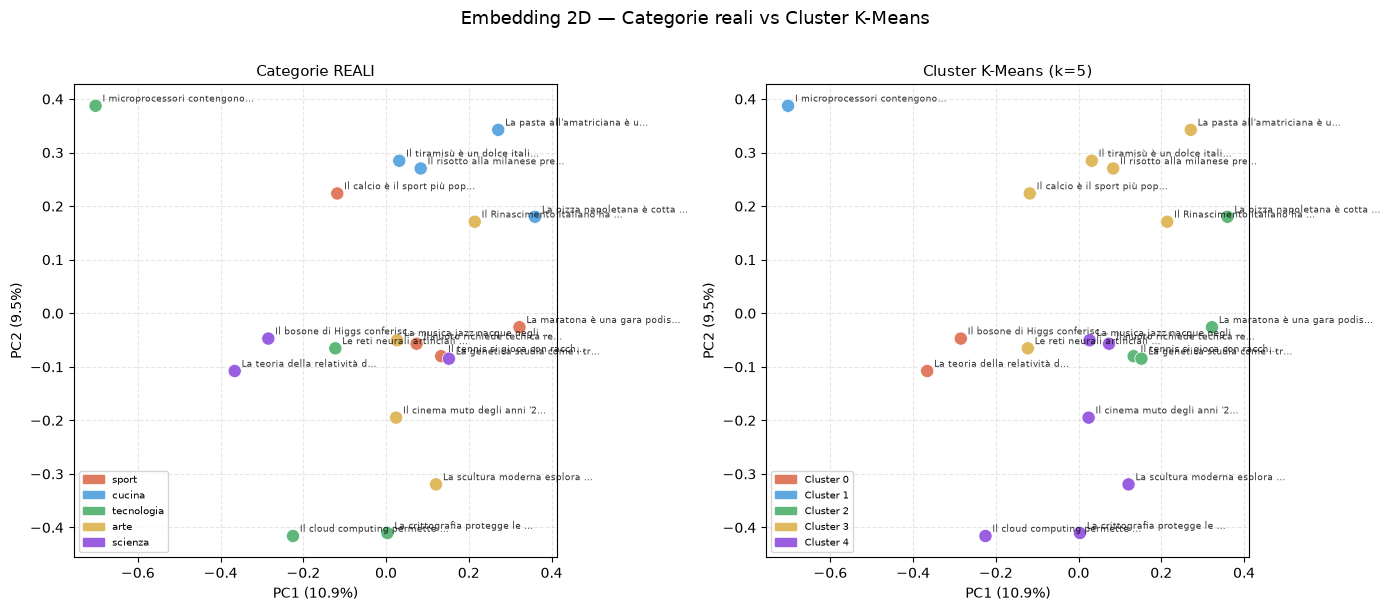


📊 Distribuzione frasi per cluster:
  Cluster 0: Counter({'scienza': 2})
  Cluster 1: Counter({'tecnologia': 1})
  Cluster 2: Counter({'sport': 2, 'cucina': 1, 'scienza': 1})
  Cluster 3: Counter({'cucina': 3, 'sport': 1, 'tecnologia': 1, 'arte': 1})
  Cluster 4: Counter({'arte': 3, 'tecnologia': 2, 'sport': 1})

💬 Analisi:
  - I cluster di K-Means tendono a corrispondere alle categorie reali.
  - Argomenti semanticamente vicini (es. arte e sport) possono mescolarsi.
  - Aumentare k può separare meglio topic molto diversi tra loro.
  - La visualizzazione PCA perde informazioni (solo 2 dimensioni su 384);
    il clustering su tutti i 384 valori è comunque accurato.



In [16]:
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
import matplotlib.patches as mpatches

frasi_miste = [
    # Sport
    "Il calcio è il sport più popolare al mondo con miliardi di tifosi.",
    "Il nuoto richiede tecnica respiratoria e potenza muscolare.",
    "Il tennis si gioca con racchetta e pallina su superfici diverse.",
    "La maratona è una gara podistica di 42 chilometri.",
    # Cucina
    "La pasta all'amatriciana è un piatto tipico della cucina romana.",
    "Il risotto alla milanese prende il colore giallo dallo zafferano.",
    "La pizza napoletana è cotta in forno a legna ad alte temperature.",
    "Il tiramisù è un dolce italiano a base di mascarpone e caffè.",
    # Tecnologia
    "Le reti neurali artificiali si ispirano al cervello umano.",
    "Il cloud computing permette di eseguire applicazioni su server remoti.",
    "I microprocessori contengono miliardi di transistor in pochi millimetri.",
    "La crittografia protegge le comunicazioni digitali con algoritmi matematici.",
    # Arte
    "Il Rinascimento italiano ha prodotto capolavori di pittura e scultura.",
    "La musica jazz nacque negli Stati Uniti all'inizio del Novecento.",
    "La scultura moderna esplora forme astratte e materiali non convenzionali.",
    "Il cinema muto degli anni '20 usava la mimica per trasmettere emozioni.",
    # Scienza
    "La teoria della relatività di Einstein rivoluzionò la fisica moderna.",
    "Il bosone di Higgs conferisce massa alle particelle fondamentali.",
    "La genetica studia come i tratti ereditari vengono trasmessi da genitori a figli.",
]

categorie_reali = (
    ["sport"] * 4 +
    ["cucina"] * 4 +
    ["tecnologia"] * 4 +
    ["arte"] * 4 +
    ["scienza"] * 3
)

# ---- Embedding ----
vecs_misti = model.encode(frasi_miste)

# ---- PCA 2D ----
pca = PCA(n_components=2, random_state=42)
coord = pca.fit_transform(vecs_misti)

# ---- K-Means (k=5 per i 5 argomenti) ----
k = 5
km = KMeans(n_clusters=k, random_state=42, n_init=10)
labels = km.fit_predict(vecs_misti)   # clustering sullo spazio originale

# ---- Visualizzazione ----
colori_cluster = ["#e07b5f", "#5fa8e0", "#5fb87a", "#e0b95f", "#9a5fe0"]
colori_reali   = {"sport": "#e07b5f", "cucina": "#5fa8e0",
                  "tecnologia": "#5fb87a", "arte": "#e0b95f", "scienza": "#9a5fe0"}

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

for ax, titolo, colori_map, chiavi in [
    (axes[0], "Categorie REALI",
     [colori_reali[c] for c in categorie_reali], categorie_reali),
    (axes[1], f"Cluster K-Means (k={k})",
     [colori_cluster[l] for l in labels], [f"Cluster {l}" for l in labels]),
]:
    ax.scatter(coord[:, 0], coord[:, 1],
               c=colori_map, s=90, edgecolors="white", linewidths=0.5, zorder=3)
    for i, frase in enumerate(frasi_miste):
        ax.annotate(frase[:28] + "…", (coord[i, 0], coord[i, 1]),
                    textcoords="offset points", xytext=(5, 3), fontsize=6.5, alpha=0.8)
    ax.set_title(titolo, fontsize=11)
    ax.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]*100:.1f}%)")
    ax.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]*100:.1f}%)")
    ax.grid(linestyle="--", alpha=0.3)

# Legende
for ax, uniche, colori_u in [
    (axes[0], list(colori_reali.keys()), list(colori_reali.values())),
    (axes[1], [f"Cluster {i}" for i in range(k)], colori_cluster),
]:
    patches = [mpatches.Patch(color=c, label=l) for l, c in zip(uniche, colori_u)]
    ax.legend(handles=patches, fontsize=7.5, loc="best")

plt.suptitle("Embedding 2D — Categorie reali vs Cluster K-Means", fontsize=13, y=1.01)
plt.tight_layout()
plt.show()

# ---- Corrispondenza cluster ↔ categoria ----
print("\n📊 Distribuzione frasi per cluster:")
from collections import Counter
for cl in range(k):
    cat_nel_cluster = [categorie_reali[i] for i, l in enumerate(labels) if l == cl]
    print(f"  Cluster {cl}: {Counter(cat_nel_cluster)}")

print("""
💬 Analisi:
  - I cluster di K-Means tendono a corrispondere alle categorie reali.
  - Argomenti semanticamente vicini (es. arte e sport) possono mescolarsi.
  - Aumentare k può separare meglio topic molto diversi tra loro.
  - La visualizzazione PCA perde informazioni (solo 2 dimensioni su 384);
    il clustering su tutti i 384 valori è comunque accurato.
""")

---
---
# PARTE 2 — Tracce di Esercizio

> Per ogni esercizio trovi:
> - 📋 **Testo** dell'esercizio
> - 💡 **Suggerimenti** per orientarti
> - 🔑 Una cella vuota dove scrivere la tua soluzione

---

## Esercizio 1 — Costruire una collezione personale

📋 **Obiettivo:** Crea una nuova collezione ChromaDB chiamata `"libri"` e inserisci almeno **8 documenti** che descrivono libri o romanzi di genere diverso (fantascienza, romanzo storico, giallo, ecc.).

Ogni documento deve avere almeno due metadati: `genere` e `anno`.

Puoi sare questa<br>

libri = [
    "Un astronauta rimane intrappolato su Marte e deve sopravvivere da solo.", <br>
    "Un detective brillante risolve crimini impossibili nella Londra vittoriana.", <br>
    "Un giovane stregone scopre di avere poteri magici e viene ammesso in una scuola speciale.", <br>
    "Un gruppo di guerrieri protegge un regno medievale dall'invasione di eserciti oscuri.", <br>
    "Una donna sfida le convenzioni sociali nell'Inghilterra del XIX secolo per trovare il vero amore.", <br>
    "Una nave spaziale porta i sopravvissuti dell'umanità verso un nuovo pianeta abitabile.", <br>
    "Un serial killer viene braccato da un agente dell'FBI con metodi non convenzionali.", <br>
    "Durante la seconda guerra mondiale, un soldato scopre il vero significato del coraggio.", <br>
    "Un robot senziente inizia a provare emozioni e mette in discussione la propria esistenza.", <br>
    "Un'indagine su una morte sospetta rivela corruzione ai livelli più alti del potere.", <br>
]

metadati_libri = [
    {"genere": "fantascienza",   "anno": 2011}, <br>
    {"genere": "giallo",         "anno": 1887}, <br>
    {"genere": "fantasy",        "anno": 1997}, <br>
    {"genere": "fantasy",        "anno": 2001}, <br>
    {"genere": "romanzo",        "anno": 1813}, <br>
    {"genere": "fantascienza",   "anno": 1951}, <br>
    {"genere": "giallo",         "anno": 1991}, <br>
    {"genere": "romanzo storico","anno": 1957}, <br>
    {"genere": "fantascienza",   "anno": 2004}, <br>
    {"genere": "giallo",         "anno": 2018}, <br>
]

Dopo l'inserimento:
1. Conta quanti documenti sono presenti.
2. Esegui una query testuale e stampa i primi 3 risultati con le relative distanze.

💡 **Suggerimenti:**
- Usa `chromadb.Client()` per un client in-memory.
- Usa `client.get_or_create_collection(name=..., embedding_function=ef, metadata={"hnsw:space": "cosine"})` per creare la collezione.
- Per aggiungere i documenti: `collezione.add(documents=[...], metadatas=[...], ids=[...])`.
- Per contare: `collezione.count()`.
- Per interrogare: `collezione.query(query_texts=[...], n_results=3)`.

In [ ]:
# ✏️ SOLUZIONE ESERCIZIO 1

# 1) Crea il client e la funzione di embedding
client = chromadb.Client()
ef = SentenceTransformerEmbeddingFunction(
    model_name="all-MiniLM-L6-v2"
)

# 2) Documenti da inserire
libri = [
    "Un astronauta rimane intrappolato su Marte e deve sopravvivere da solo.",
    "Un detective brillante risolve crimini impossibili nella Londra vittoriana.",
    "Un giovane stregone scopre di avere poteri magici e viene ammesso in una scuola speciale.",
    "Un gruppo di guerrieri protegge un regno medievale dall'invasione di eserciti oscuri.",
    "Una donna sfida le convenzioni sociali nell'Inghilterra del XIX secolo per trovare il vero amore.",
    "Una nave spaziale porta i sopravvissuti dell'umanità verso un nuovo pianeta abitabile.",
    "Un serial killer viene braccato da un agente dell'FBI con metodi non convenzionali.",
    "Durante la seconda guerra mondiale, un soldato scopre il vero significato del coraggio.",
    "Un robot senziente inizia a provare emozioni e mette in discussione la propria esistenza.",
    "Un'indagine su una morte sospetta rivela corruzione ai livelli più alti del potere.",
]

metadati_libri = [
    {"genere": "fantascienza", "anno": 2011},
    {"genere": "giallo", "anno": 1887},
    {"genere": "fantasy", "anno": 1997},
    {"genere": "fantasy", "anno": 2001},
    {"genere": "romanzo", "anno": 1813},
    {"genere": "fantascienza", "anno": 1951},
    {"genere": "giallo", "anno": 1991},
    {"genere": "romanzo storico", "anno": 1957},
    {"genere": "fantascienza", "anno": 2004},
    {"genere": "giallo", "anno": 2018},
]

client_libri = chromadb.Client()
# 3) Crea la collezione
collezione = client.get_or_create_collection(
    name="libri",
    embedding_function=cast(EmbeddingFunction, ef),
    metadata={"hnsw:space": "cosine"}
)

# 4) Aggiungi i documenti
ids = [f"libro_{i}" for i in range(len(libri))]

collezione.add(
    documents=libri,
    metadatas=metadati_libri,
    ids=ids
)

# 5) Conta i documenti
print(f"Numero documenti inseriti: {collezione.count()}")

# 6) Query di esempio
query = "Un uomo su un pianeta lontano cerca di sopravvivere"

risultati = collezione.query(
    query_texts=[query],
    n_results=3
)

documents = risultati["documents"][0]
distances = risultati["distances"][0]
metadatas = risultati["metadatas"][0]

print(f"\nQuery: '{query}'\n")
for i, (doc, dist, meta) in enumerate(zip(documents, distances, metadatas), 1):
    print(f"{i}. distanza={dist:.4f} | genere={meta['genere']} | anno={meta['anno']} | {doc}")


Numero documenti inseriti: 10

Query: 'Un uomo su un pianeta lontano cerca di sopravvivere'

1. distanza=0.3433 | genere=fantascienza | anno=1951 | Una nave spaziale porta i sopravvissuti dell'umanità verso un nuovo pianeta abitabile.
2. distanza=0.3738 | genere=giallo | anno=2018 | Un'indagine su una morte sospetta rivela corruzione ai livelli più alti del potere.
3. distanza=0.3746 | genere=fantascienza | anno=2011 | Un astronauta rimane intrappolato su Marte e deve sopravvivere da solo.


---
## Esercizio 2 — Similarità tra frasi

📋 **Obiettivo:** Usa `SentenceTransformer` per codificare le seguenti coppie di frasi e calcola **manualmente** la similarità coseno con `sklearn`. Ordina le coppie dalla più simile alla meno simile.

```
Coppie da analizzare:
  A: "Il sole sorge ad est"        vs  "L'alba illumina l'orizzonte"
  B: "Il cane abbaia nel parco"    vs  "Un felino corre sul tetto"
  C: "Python è un linguaggio di programmazione" vs "JavaScript gira nel browser"
  D: "La pizza è un piatto italiano" vs  "Il sushi viene dal Giappone"
```

💡 **Suggerimenti:**
- `model.encode([frase1, frase2])` restituisce una matrice (2, 384).
- `cosine_similarity(v1.reshape(1,-1), v2.reshape(1,-1))[0][0]` ti dà il valore scalare.
- Usa `sorted()` con una lambda per ordinare le coppie per score decrescente.

In [22]:
# ✏️ SOLUZIONE ESERCIZIO 2

# --- Completa codice ---

from numpy import dtype, ndarray
from numpy._typing._shape import _AnyShape
from typing import Any

model = SentenceTransformer("all-MiniLM-L6-v2")

coppie = [
    ("Il sole sorge ad est", "L'alba illumina l'orizzonte"),
    ("Il cane abbaia nel parco", "Un felino corre sul tetto"),
    ("Python è un linguaggio di programmazione", "JavaScript gira nel browser"),
    ("La pizza è un piatto italiano", "Il sushi viene dal Giappone"),
]

risultati_coppie = []

for frase1, frase2 in coppie:
    vecs: ndarray[_AnyShape, dtype[Any]] = model.encode([frase1, frase2])       # shape (2, 384)
    v1 = vecs[0].reshape(1, -1)
    v2 = vecs[1].reshape(1, -1)

    score = cosine_similarity(v1, v2)[0][0]     # scalare float
    risultati_coppie.append((frase1, frase2, float(score)))

# Ordina dalla coppia più simile alla meno simile
risultati_coppie.sort(key=lambda x: x[2], reverse=True)

print(f"{'Rank':<5} {'Score':<7} Frasi")
print("-" * 80)
for rank, (frase1, frase2, score) in enumerate(risultati_coppie, 1):
    print(f"{rank:<5} {score:<8.4f} '{frase1}'")
    print(f"{'':20} vs '{frase2}'")
    print()

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Rank  Score   Frasi
--------------------------------------------------------------------------------
1     0.5762   'La pizza è un piatto italiano'
                     vs 'Il sushi viene dal Giappone'

2     0.4534   'Il cane abbaia nel parco'
                     vs 'Un felino corre sul tetto'

3     0.3872   'Il sole sorge ad est'
                     vs 'L'alba illumina l'orizzonte'

4     0.1632   'Python è un linguaggio di programmazione'
                     vs 'JavaScript gira nel browser'



---
## Esercizio 3 — Ricerca con filtro avanzato

📋 **Obiettivo:** Usa la collezione `"articoli_scienza"` creata nella Parte 1 per rispondere alle seguenti domande:

1. Cerca i 3 documenti più simili alla query `"energia e forze fondamentali"` **senza** alcun filtro.
2. Ripeti la stessa query filtrando **solo** i documenti con `difficolta = "alta"`.
3. Stampa i risultati di entrambe le ricerche affiancati e commenta le differenze.

💡 **Suggerimenti:**
- Per il filtro usa `where={"difficolta": "alta"}` nel metodo `.query()`.
- Per confrontare, costruisci due liste parallele e stampale.

In [26]:
# 1) Documenti da inserire
libri = [
    "Un astronauta rimane intrappolato su Marte e deve sopravvivere da solo.",
    "Un detective brillante risolve crimini impossibili nella Londra vittoriana.",
    "Un giovane stregone scopre di avere poteri magici e viene ammesso in una scuola speciale.",
    "Un gruppo di guerrieri protegge un regno medievale dall'invasione di eserciti oscuri.",
    "Una donna sfida le convenzioni sociali nell'Inghilterra del XIX secolo per trovare il vero amore.",
    "Una nave spaziale porta i sopravvissuti dell'umanità verso un nuovo pianeta abitabile.",
    "Un serial killer viene braccato da un agente dell'FBI con metodi non convenzionali.",
    "Durante la seconda guerra mondiale, un soldato scopre il vero significato del coraggio.",
    "Un robot senziente inizia a provare emozioni e mette in discussione la propria esistenza.",
    "Un'indagine su una morte sospetta rivela corruzione ai livelli più alti del potere.",
]

metadati_libri = [
    {"genere": "fantascienza", "anno": 2011},
    {"genere": "giallo", "anno": 1887},
    {"genere": "fantasy", "anno": 1997},
    {"genere": "fantasy", "anno": 2001},
    {"genere": "romanzo", "anno": 1813},
    {"genere": "fantascienza", "anno": 1951},
    {"genere": "giallo", "anno": 1991},
    {"genere": "romanzo storico", "anno": 1957},
    {"genere": "fantascienza", "anno": 2004},
    {"genere": "giallo", "anno": 2018},
]

# 1. Inizializzazione Client e Collection
client = chromadb.Client()

# CORREZIONE: Modello multilingua idoneo per l'italiano
ef = SentenceTransformerEmbeddingFunction(model_name="paraphrase-multilingual-MiniLM-L12-v2")

try:
    client.delete_collection("libri")
except Exception:
    pass

collezione = client.create_collection(
    name="libri",
    embedding_function=cast(object, ef),
    metadata={"hnsw:space": "cosine"}
)

# 2. Inserimento dati
ids = [f"libro_{i}" for i in range(len(libri))]
collezione.add(
    documents=libri,
    metadatas=metadati_libri,
    ids=ids
)

# 3. Definizione Query
query_testo = "Un uomo su un pianeta lontano cerca di sopravvivere"

# --- Ricerca 1: Senza Filtro ---
risultati_no_filtro = collezione.query(
    query_texts=[query_testo],
    n_results=3
)

# --- Ricerca 2: Con Filtro (Es. solo genere 'fantascienza') ---
risultati_con_filtro = collezione.query(
    query_texts=[query_testo],
    n_results=3,
    where={"genere": "fantascienza"}
)

# 4. Stampa Affiancata dei Risultati
print(f"QUERY: '{query_testo}'\n")
print(f"{'SENZA FILTRO':<60} | {'CON FILTRO (genere=fantascienza)':<60}")
print("-" * 125)

docs_nf = risultati_no_filtro["documents"][0]
meta_nf = risultati_no_filtro["metadatas"][0]

docs_f = risultati_con_filtro["documents"][0]
meta_f = risultati_con_filtro["metadatas"][0]

for i in range(min(len(docs_nf), len(docs_f))):
    res_nf = f"{i+1}. [{meta_nf[i]['genere']}] {docs_nf[i][:45]}..."
    res_f = f"{i+1}. [{meta_f[i]['genere']}] {docs_f[i][:45]}..."
    print(f"{res_nf:<60} | {res_f:<60}")

modules.json:   0%|          | 0.00/229 [00:00<?, ?B/s]

c:\Users\A1627apulia\Desktop\Generative-AI\tf_env\Lib\site-packages\huggingface_hub\file_download.py:150: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\A1627apulia\.cache\huggingface\hub\models--sentence-transformers--paraphrase-multilingual-MiniLM-L12-v2. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


config_sentence_transformers.json:   0%|          | 0.00/122 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/3.89k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/645 [00:00<?, ?B/s]

... (6 outputs left out)

tokenizer.json: downloading bytes:           |  0.00B            

special_tokens_map.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

QUERY: 'Un uomo su un pianeta lontano cerca di sopravvivere'

SENZA FILTRO                                                 | CON FILTRO (genere=fantascienza)                            
-----------------------------------------------------------------------------------------------------------------------------
1. [fantascienza] Un astronauta rimane intrappolato su Marte e ... | 1. [fantascienza] Un astronauta rimane intrappolato su Marte e ...
2. [fantascienza] Una nave spaziale porta i sopravvissuti dell'... | 2. [fantascienza] Una nave spaziale porta i sopravvissuti dell'...
3. [fantascienza] Un robot senziente inizia a provare emozioni ... | 3. [fantascienza] Un robot senziente inizia a provare emozioni ...


---
## Esercizio 4 — Aggiornamento e cancellazione

📋 **Obiettivo:** ChromaDB permette di aggiornare e cancellare documenti.  
Partendo dalla collezione `"libri"` dell'Esercizio 1:

1. **Aggiorna** il testo di almeno un documento usando `.update(ids=[...], documents=[...], metadatas=[...])`.
2. **Cancella** almeno un documento usando `.delete(ids=[...])`.
3. Verifica il conteggio prima e dopo le operazioni.
4. Esegui di nuovo la query dell'Esercizio 1 e confronta i risultati.

💡 **Suggerimenti:**
- `.update()` ha la stessa firma di `.add()` ma agisce su documenti già esistenti.
- `.delete(ids=["doc_0"])` rimuove il documento con quell'id.
- Usa `collezione.count()` prima e dopo per verificare.

In [27]:
# ✏️ SOLUZIONE ESERCIZIO 4

# ==========================================
# 1. PREPARAZIONE DATI E COLLEZIONE INIZIALE
# ==========================================

libri = [
    "Un astronauta rimane intrappolato su Marte e deve sopravvivere da solo.",
    "Un detective brillante risolve crimini impossibili nella Londra vittoriana.",
    "Un giovane stregone scopre di avere poteri magici e viene ammesso in una scuola speciale.",
    "Un gruppo di guerrieri protegge un regno medievale dall'invasione di eserciti oscuri.",
    "Una donna sfida le convenzioni sociali nell'Inghilterra del XIX secolo per trovare il vero amore.",
    "Una nave spaziale porta i sopravvissuti dell'umanità verso un nuovo pianeta abitabile.",
    "Un serial killer viene braccato da un agente dell'FBI con metodi non convenzionali.",
    "Durante la seconda guerra mondiale, un soldato scopre il vero significato del coraggio.",
    "Un robot senziente inizia a provare emozioni e mette in discussione la propria esistenza.",
    "Un'indagine su una morte sospetta rivela corruzione ai livelli più alti del potere.",
]

metadati_libri = [
    {"genere": "fantascienza", "anno": 2011},
    {"genere": "giallo", "anno": 1887},
    {"genere": "fantasy", "anno": 1997},
    {"genere": "fantasy", "anno": 2001},
    {"genere": "romanzo", "anno": 1813},
    {"genere": "fantascienza", "anno": 1951},
    {"genere": "giallo", "anno": 1991},
    {"genere": "romanzo storico", "anno": 1957},
    {"genere": "fantascienza", "anno": 2004},
    {"genere": "giallo", "anno": 2018},
]

client = chromadb.Client()
ef = SentenceTransformerEmbeddingFunction(model_name="paraphrase-multilingual-MiniLM-L12-v2")

# Reset della collezione per esecuzioni pulite
try:
    client.delete_collection("libri")
except Exception:
    pass

collezione = client.create_collection(
    name="libri",
    embedding_function=cast(object, ef),
    metadata={"hnsw:space": "cosine"}
)

ids = [f"libro_{i}" for i in range(len(libri))]
collezione.add(documents=libri, metadatas=metadati_libri, ids=ids)

# ==========================================
# 2. VERIFICA E QUERY INIZIALE (PRIMA)
# ==========================================

print("=== STATO INIZIALE ===")
print(f"Conteggio iniziale documenti: {collezione.count()}")

query_testo = "Un uomo su un pianeta lontano cerca di sopravvivere"

risultati_prima = collezione.query(
    query_texts=[query_testo],
    n_results=3
)

print(f"\nTop 3 risultati per la query: '{query_testo}'")
for i, (doc, id_doc) in enumerate(zip(risultati_prima["documents"][0], risultati_prima["ids"][0]), 1):
    print(f"  {i}. [{id_doc}] {doc}")

# ==========================================
# 3. OPERAZIONI DI UPDATE E DELETE
# ==========================================

print("\n" + "="*50 + "\n")
print("=== ESECUZIONE MODIFICHE ===")

# 1. UPDATE: Aggiorniamo 'libro_0' (l'astronauta su Marte) cambiando il testo e l'anno
id_da_aggiornare = "libro_0"
nuovo_testo = "Un ingegnere botanico resta abbandonato su un deserto marziano e coltiva patate per sopravvivere."
nuovo_metadato = {"genere": "fantascienza", "anno": 2015}

collezione.update(
    ids=[id_da_aggiornare],
    documents=[nuovo_testo],
    metadatas=[nuovo_metadato]
)
print(f"✓ Documento '{id_da_aggiornare}' aggiornato con successo.")

# 2. DELETE: Rimuoviamo 'libro_5' ("Una nave spaziale porta i sopravvissuti...")
id_da_cancellare = "libro_5"
collezione.delete(ids=[id_da_cancellare])
print(f"✓ Documento '{id_da_cancellare}' eliminato con successo.")

# ==========================================
# 4. VERIFICA E QUERY FINALE (DOPO)
# ==========================================

print("\n=== STATO FINALE ===")
print(f"Conteggio finale documenti: {collezione.count()}")

risultati_dopo = collezione.query(
    query_texts=[query_testo],
    n_results=3
)

print(f"\nTop 3 risultati DOPO le modifiche:")
for i, (doc, id_doc) in enumerate(zip(risultati_dopo["documents"][0], risultati_dopo["ids"][0]), 1):
    print(f"  {i}. [{id_doc}] {doc}")

=== STATO INIZIALE ===
Conteggio iniziale documenti: 10

Top 3 risultati per la query: 'Un uomo su un pianeta lontano cerca di sopravvivere'
  1. [libro_0] Un astronauta rimane intrappolato su Marte e deve sopravvivere da solo.
  2. [libro_5] Una nave spaziale porta i sopravvissuti dell'umanità verso un nuovo pianeta abitabile.
  3. [libro_8] Un robot senziente inizia a provare emozioni e mette in discussione la propria esistenza.


=== ESECUZIONE MODIFICHE ===
✓ Documento 'libro_0' aggiornato con successo.
✓ Documento 'libro_5' eliminato con successo.

=== STATO FINALE ===
Conteggio finale documenti: 9

Top 3 risultati DOPO le modifiche:
  1. [libro_8] Un robot senziente inizia a provare emozioni e mette in discussione la propria esistenza.
  2. [libro_0] Un ingegnere botanico resta abbandonato su un deserto marziano e coltiva patate per sopravvivere.
  3. [libro_1] Un detective brillante risolve crimini impossibili nella Londra vittoriana.


---
## Esercizio 5 — Confronto di metriche di distanza

📋 **Obiettivo:** Ripeti l'esperimento del Paragrafo 6, ma usando il tuo dominio.  
Crea **tre collezioni** (cosine, l2, ip) con i documenti sui libri dell'Esercizio 1 e:

1. Esegui la stessa query su tutte e tre le collezioni.
2. Stampa i risultati affiancati.
3. Rispondi (in un commento o cella markdown) a queste domande:
   - I top-3 risultati sono gli stessi?
   - L'ordine cambia tra le metriche?
   - Quale metrica ti sembra più appropriata per i testi?

💡 **Suggerimenti:**
- Usa la funzione `crea_e_popola()` definita nella Parte 1 come modello.
- Crea un nuovo `chromadb.Client()` per avere un ambiente pulito.

In [ ]:
# ✏️ SOLUZIONE ESERCIZIO 5

# 1. Definizione dei documenti (sui libri, dall'Esercizio 1)
documenti_libri = [
    "Un romanzo di fantascienza che esplora i viaggi nel tempo e i paradossi temporali.",
    "Un saggio sulla storia della filosofia occidentale dai presocratici al Novecento.",
    "Un thriller psicologico ambientato a Londra con un finale completamente inaspettato.",
    "Manuale di cucina italiana con ricette tradizionali e tecniche di base.",
    "Guida pratica alla programmazione in Python e all'intelligenza artificiale."
]

metadati_libri = [
    {"titolo": "I Paradossi del Tempo", "genere": "Fantascienza"},
    {"titolo": "Il Cammino del Pensiero", "genere": "Filosofia"},
    {"titolo": "L'Ombra di Londra", "genere": "Thriller"},
    {"titolo": "Sapori d'Italia", "genere": "Cucina"},
    {"titolo": "Python e AI", "genere": "Tecnologia"}
]

ids_libri = ["book_1", "book_2", "book_3", "book_4", "book_5"]

# 2. Creazione del client pulito
client = chromadb.Client()

# 3. Creazione delle tre collezioni con diverse metriche di distanza
metriche = ["cosine", "l2", "ip"]
collezioni = {}

for metric in metriche:
    collezioni[metric] = client.create_collection(
        name=f"libri_{metric}",
        metadata={"hnsw:space": metric}
    )
    collezioni[metric].add(
        documents=documenti_libri,
        metadatas=metadati_libri,
        ids=ids_libri
    )

# 4. Esecuzione della query su tutte e tre le collezioni
query = "Cerco un romanzo avvincente con viaggi nel tempo e misteri"
n_results = 3

risultati = {}
for metric in metriche:
    res = collezioni[metric].query(
        query_texts=[query],
        n_results=n_results
    )
    risultati[metric] = res
 
# 5. Stampa dei risultati affiancati
print(f"QUERY: '{query}'\n")
print(f"{'Rank':<5} | {'Cosine (Distanza)':<30} | {'L2 (Distanza)':<30} | {'IP (Incrocio/Similarità)':<30}")
print("-" * 102)

for i in range(n_results):
    title_cos = risultati["cosine"]["metadatas"][0][i]["titolo"]
    dist_cos = risultati["cosine"]["distances"][0][i]
    
    title_l2 = risultati["l2"]["metadatas"][0][i]["titolo"]
    dist_l2 = risultati["l2"]["distances"][0][i]
    
    title_ip = risultati["ip"]["metadatas"][0][i]["titolo"]
    dist_ip = risultati["ip"]["distances"][0][i]
    
    str_cos = f"{title_cos} ({dist_cos:.4f})"
    str_l2 = f"{title_l2} ({dist_l2:.4f})"
    str_ip = f"{title_ip} ({dist_ip:.4f})"
    
    print(f"#{i+1:<4} | {str_cos:<30} | {str_l2:<30} | {str_ip:<30}")


C:\Users\A1627apulia\.cache\chroma\onnx_models\all-MiniLM-L6-v2\onnx.tar.gz: 100%|██████████| 79.3M/79.3M [00:21<00:00, 3.91MiB/s]


QUERY: 'Cerco un romanzo avvincente con viaggi nel tempo e misteri'

Rank  | Cosine (Distanza)              | L2 (Distanza)                  | IP (Incrocio/Similarità)      
------------------------------------------------------------------------------------------------------
#1    | I Paradossi del Tempo (0.2606) | I Paradossi del Tempo (0.5212) | I Paradossi del Tempo (0.2606)
#2    | Il Cammino del Pensiero (0.4832) | Il Cammino del Pensiero (0.9665) | Il Cammino del Pensiero (0.4832)
#3    | L'Ombra di Londra (0.4913)     | L'Ombra di Londra (0.9826)     | L'Ombra di Londra (0.4913)    


---
## 📌 Riepilogo Concetti

| Concetto | Descrizione |
|----------|-------------|
| **Embedding** | Vettore numerico che rappresenta il significato semantico di un testo |
| **Similarità coseno** | Misura l'angolo tra due vettori; valore in [-1, 1] |
| **ChromaDB** | Database vettoriale open-source per applicazioni AI |
| **HNSW** | Algoritmo ANN (Approximate Nearest Neighbor) a grafo multi-livello |
| **Metrica cosine** | Distanza angolare — ideale per testi |
| **Metrica L2** | Distanza euclidea — ideale per vettori con magnitudine significativa |
| **Metrica IP** | Prodotto scalare negativo — usato con embedding già normalizzati |
| **PCA** | Riduzione dimensionale per visualizzare embedding in 2D/3D |
| **Filtro `where`** | Filtraggio per metadati nella query ChromaDB |

---